In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
SEED = 123
rng = np.random.default_rng(SEED)
N_CITIES = 20

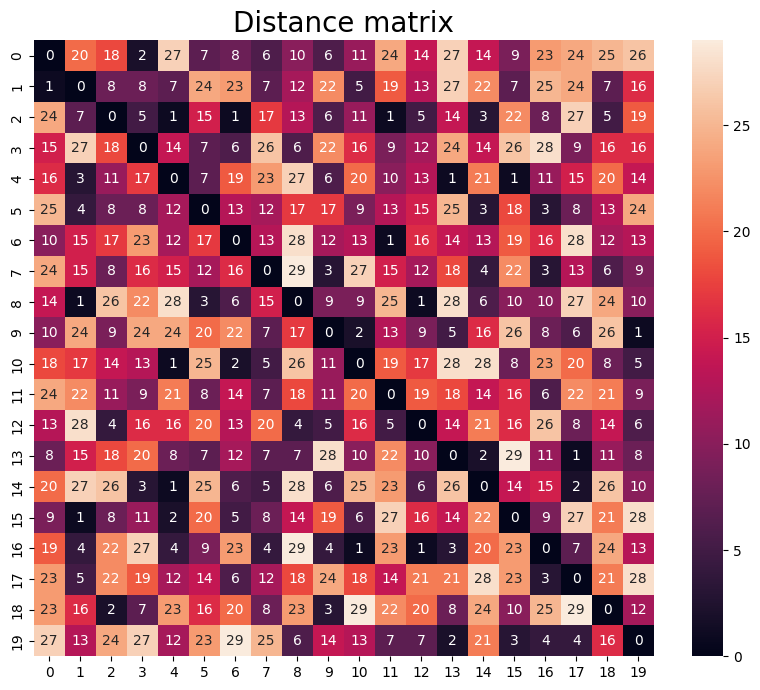

In [12]:
def initialize_distance_matrix(n_cities: int) -> np.ndarray:
    dist_matrix = rng.integers(1, 30, size=(n_cities, n_cities))
    np.fill_diagonal(dist_matrix, 0)
    return dist_matrix

dist_matrix = initialize_distance_matrix(N_CITIES)

plt.figure(figsize=(10,8))
plt.title('Distance matrix', fontsize=20)
sns.heatmap(dist_matrix, annot=True)
plt.show()

In [13]:
class TSPSubject:
    def __init__(self, path: np.ndarray):
        self.path = np.asarray(path, dtype=np.int32)
        self.fitness: float | None = None

    def evaluate_fitness(self, dist_matrix: np.ndarray):
        if self.fitness is not None:
            return 
            
        route = np.concatenate(([0], self.path, [0]))
        
        cost = np.sum(dist_matrix[route[:-1], route[1:]])
        self.fitness = float(cost)

    def __repr__(self) -> str:
        return f'TSPSubject(fitness={self.fitness})'

def init_population(pop_size: int, n_cities: int) -> list[TSPSubject]:
    population = []
    base_path = np.arange(1, n_cities) 
    
    for _ in range(pop_size):
        shuffled_path = rng.permutation(base_path)
        population.append(TSPSubject(shuffled_path))
        
    return population

In [14]:
def tournament_selection(population: list[TSPSubject], k: int = 5) -> TSPSubject:
    tournament = rng.choice(population, size=k, replace=False)
    winner = min(tournament, key=lambda s: s.fitness)
    return winner

def roulette_wheel_selection(population: list[TSPSubject]) -> TSPSubject:
    costs = np.array([s.fitness for s in population], dtype=np.float32)
    max_cost = np.max(costs)
    
    weights = (max_cost - costs) + 1e-6
    probabilities = weights / np.sum(weights)
    
    winner_idx = rng.choice(len(population), p=probabilities)
    return population[winner_idx]

In [15]:
def ox_crossover(parent1: TSPSubject, parent2: TSPSubject) -> tuple[TSPSubject, TSPSubject]:
    size = len(parent1.path)
    
    def generate_child(p1_path, p2_path):
        child_path = np.full(size, -1, dtype=np.int32)
        start, end = sorted(rng.choice(size, 2, replace=False))
        
        child_path[start:end] = p1_path[start:end]
        
        p2_filtered = [city for city in p2_path if city not in child_path[start:end]]
        
        idx = 0
        for i in range(size):
            if child_path[i] == -1:
                child_path[i] = p2_filtered[idx]
                idx += 1
                
        return TSPSubject(child_path)

    child1 = generate_child(parent1.path, parent2.path)
    child2 = generate_child(parent2.path, parent1.path)
    return child1, child2

def mutate(subject: TSPSubject, mutation_rate: float = 0.05) -> TSPSubject:
    if rng.random() > mutation_rate:
        return subject
        
    mutated_path = subject.path.copy()
    size = len(mutated_path)
    
    idx1, idx2 = rng.choice(size, 2, replace=False)
    mutated_path[idx1], mutated_path[idx2] = mutated_path[idx2], mutated_path[idx1]
    
    return TSPSubject(mutated_path)

Główna pętla alg. genetycznego:

1. Inicjalizacja populacji początkowej.
2. Zachowanie najlepszego osobnika .
3. Selekcja rodziców.
4. Krzyżowanie (OX1) z prawdopodobieństwem `Pc`.
5. Mutacja (Swap) z prawdopodobieństwem `Pm`.
6. Ocena nowych osobników i zastąpienie starej populacji.
7. Powrót do kroku 2.


Final best fitness: 76.0
Final route: [ 0  6 11  5 14 17 16 13  7 18  2  3  8 12  9 10 19 15  4  1  0]


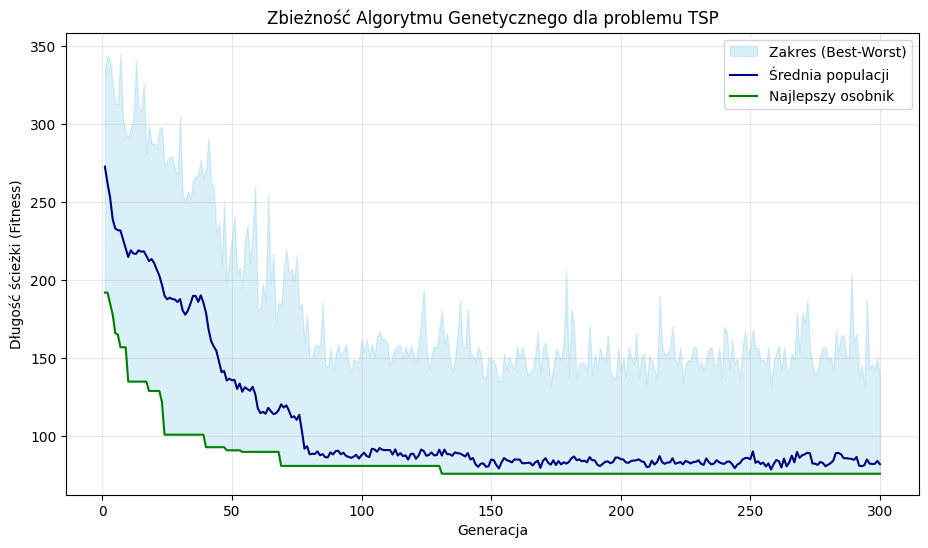

In [ ]:
_POPULATION_SIZE = 100
_GENERATIONS = 300
_CROSSOVER_PROBABILITY = 0.8
_MUTATION_PROBABILITY = 0.15

population = init_population(_POPULATION_SIZE, N_CITIES)
for subject in population:
    subject.evaluate_fitness(dist_matrix)

best_history = []
average_history = []
worst_history = []

for generation in range(_GENERATIONS):
    new_population = []
    
    best_current = min(population, key=lambda s: s.fitness)
    elite_subject = TSPSubject(best_current.path.copy())
    elite_subject.fitness = best_current.fitness 
    new_population.append(elite_subject)

    while len(new_population) < _POPULATION_SIZE:
        parent1 = tournament_selection(population, k=2)
        parent2 = tournament_selection(population, k=2)

        if rng.random() < _CROSSOVER_PROBABILITY:
            child1, child2 = ox_crossover(parent1, parent2)
        else:
            child1 = TSPSubject(parent1.path.copy())
            child2 = TSPSubject(parent2.path.copy())

        child1 = mutate(child1, _MUTATION_PROBABILITY)
        child2 = mutate(child2, _MUTATION_PROBABILITY)

        child1.evaluate_fitness(dist_matrix)
        child2.evaluate_fitness(dist_matrix)

        new_population.append(child1)
        if len(new_population) < _POPULATION_SIZE:
            new_population.append(child2)

    population = new_population
    
    population_fitness = np.array([s.fitness for s in population])
    best_subject = min(population, key=lambda s: s.fitness)
    worst_subject = max(population, key=lambda s: s.fitness)
    
    best_history.append(best_subject.fitness)
    average_history.append(np.mean(population_fitness))
    worst_history.append(worst_subject.fitness)

print(f'\nFinal best fitness: {best_history[-1]}')
print(f'Final route: {np.concatenate(([0], best_subject.path, [0]))}')

generations = np.arange(1, _GENERATIONS + 1)
plt.figure(figsize=(11, 6))
plt.fill_between(generations, best_history, worst_history, color='skyblue', alpha=0.3, label='Zakres')

plt.plot(generations, average_history, color='navy', label='Średnia populacji')
plt.plot(generations, best_history, color='green', label='Najlepszy osobnik')
plt.title('Zbieżność Algorytmu Genetycznego')
plt.xlabel('Generacja')
plt.ylabel('Długość ścieżki')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()